# Data Understanding & Exploratory Data Analysis

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os
sys.path.append(os.path.abspath("../src"))
from eda_util import churn_rate

## 2.Load the Dataset

In [2]:
cust_churn_df=pd.read_excel("../data/raw/Telco_customer_churn.xlsx")

In [3]:
cust_churn_df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## 3. Dataset Overview

In [4]:
cust_churn_df.shape

(7043, 33)

In [5]:
cust_churn_df.describe().round(2)

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00
mean,1.0,93521.96,36.28,-119.80,32.37,64.76,0.27,58.70,4400.30
std,0.0,1865.79,2.46,2.16,24.56,30.09,0.44,21.53,1183.06
min,1.0,90001.00,32.56,-124.30,0.00,18.25,0.00,5.00,2003.00
25%,1.0,92102.00,34.03,-121.82,9.00,35.50,0.00,40.00,3469.00
50%,1.0,93552.00,36.39,-119.73,29.00,70.35,0.00,61.00,4527.00
75%,1.0,95351.00,38.22,-118.04,55.00,89.85,1.00,75.00,5380.50
max,1.0,96161.00,41.96,-114.19,72.00,118.75,1.00,100.00,6500.00


## 4.Data Types

In [6]:
cust_churn_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [7]:
str_columns=cust_churn_df.dtypes[(cust_churn_df.dtypes=='str') | (cust_churn_df.dtypes=="object")]

In [8]:
str_columns

CustomerID              str
Country                 str
State                   str
City                    str
Lat Long                str
Gender                  str
Senior Citizen          str
Partner                 str
Dependents              str
Phone Service           str
Multiple Lines          str
Internet Service        str
Online Security         str
Online Backup           str
Device Protection       str
Tech Support            str
Streaming TV            str
Streaming Movies        str
Contract                str
Paperless Billing       str
Payment Method          str
Total Charges        object
Churn Label             str
Churn Reason            str
dtype: object

In [9]:
int_columns=cust_churn_df.dtypes[cust_churn_df.dtypes=='int64']

In [10]:
int_columns

Count            int64
Zip Code         int64
Tenure Months    int64
Churn Value      int64
Churn Score      int64
CLTV             int64
dtype: object

In [11]:
float_columns=cust_churn_df.dtypes[cust_churn_df.dtypes=='float64']

In [12]:
float_columns

Latitude           float64
Longitude          float64
Monthly Charges    float64
dtype: object

## 5. Missing Values

In [13]:
missing_columns=cust_churn_df.columns[(cust_churn_df.isna().sum()!=0)]
missing_columns_space=cust_churn_df.columns[cust_churn_df.isin([" ",""]).any()]

In [14]:
print(f"The column(s) with missing values(NA) [{missing_columns[0]}]")
print(f"The column(s) with empty string/spaces [{missing_columns_space[0]}]")

The column(s) with missing values(NA) [Churn Reason]
The column(s) with empty string/spaces [Total Charges]


#### Observations
- The dataset contains no explicit missing values for most predictive features. However, the `Total Charges` column contains blank string **' '** entries that represent missing values and prevent direct conversion to a numeric data type.
- The `Churn Reason` column contains missing values for customers who did not churn.
- Since `Churn Reason` is recorded only after churn occurs, it will be excluded during preprocessing to prevent target leakage.

## 6. Duplicate Records

In [15]:
cust_churn_df.duplicated().sum()

np.int64(0)

## 7.Target Variable Analysis

In [16]:
counts=cust_churn_df['Churn Value'].value_counts().sort_index()

In [17]:
counts

Churn Value
0    5174
1    1869
Name: count, dtype: int64

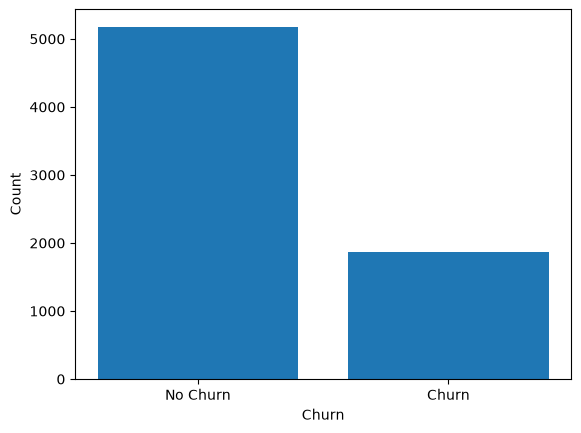

In [18]:
plt.bar(['No Churn', 'Churn'], counts)
plt.xlabel('Churn')
plt.ylabel('Count')
plt.show()

#### Observations
- Approximately 73% of customers did not churn, while 27% did.
- The target variable is imbalanced.
- Predicting customers who will churn is more important than maximizing the overall accuracy.

In [19]:
counts.index

Index([0, 1], dtype='int64', name='Churn Value')

## 8.Numerical Featues

In [20]:
cust_churn_df['Tenure Months'].value_counts()

Tenure Months
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: count, Length: 73, dtype: int64

In [21]:
cust_churn_df['Monthly Charges'].value_counts()

Monthly Charges
20.05     61
19.85     45
19.95     44
19.90     44
20.00     43
          ..
43.05      1
72.00      1
108.35     1
63.10      1
78.70      1
Name: count, Length: 1585, dtype: int64

In [22]:
cust_churn_df['Total Charges'].value_counts()

Total Charges
20.2      11
          11
19.75      9
19.9       8
19.65      8
          ..
1419.4     1
1990.5     1
7362.9     1
346.45     1
6844.5     1
Name: count, Length: 6531, dtype: int64

### Tenure Months Distribution

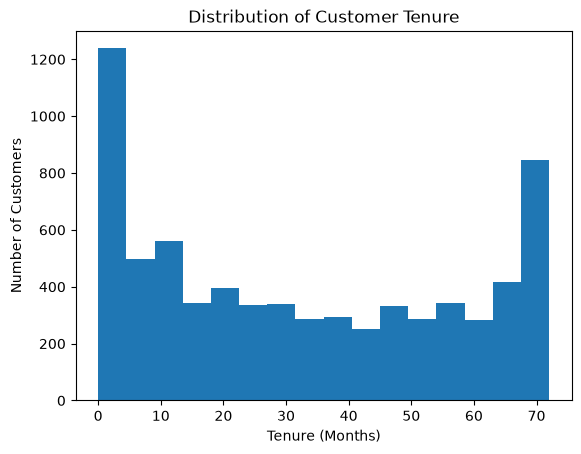

In [23]:
plt.hist(cust_churn_df['Tenure Months'],bins='auto')
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Tenure")
plt.show()

#### Observations
- The tenure distribution is bimodal, with a large concentration of customers in the early months of service and another concentration near the maximum tenure. Customer counts remain relatively stable across the middle tenure ranges.

### Tenure vs. Churn

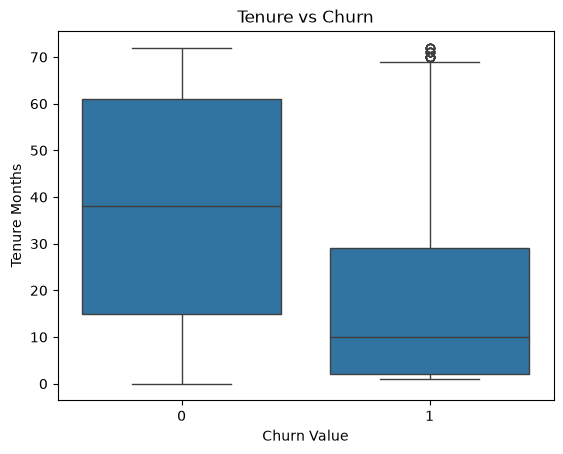

In [24]:
sns.boxplot(x='Churn Value',y='Tenure Months',data=cust_churn_df)
plt.title('Tenure vs Churn')
plt.show()

#### Observations
- Customers who churn generally have much shorter tenure than customers who remain.
- The middle 50% of churned customers have substantially lower tenure than the middle 50% of retained customers.
- Although churn is more common among newer customers, a small number of long-term customers also leave the company.
- Overall, customer tenure appears to be a strong candidate predictor for churn and will likely be an important feature during model development.

### Montly Charges

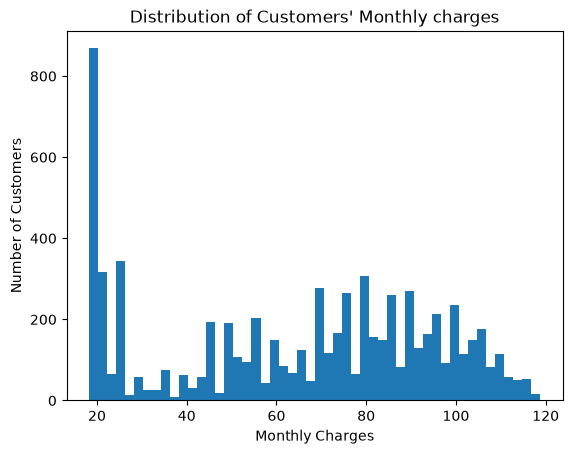

In [25]:
plt.hist(cust_churn_df['Monthly Charges'],bins=50)
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customers' Monthly charges")
plt.show()

#### Observations
- The distribution of monthly charges spans a wide range of values, with the highest concentration of customers paying around `$15–$20` per month. Beyond this range, customer counts fluctuate across different charge levels, indicating that customers subscribe to a variety of pricing plans rather than clustering around a single monthly fee.

### Monthly Charges vs. Churn

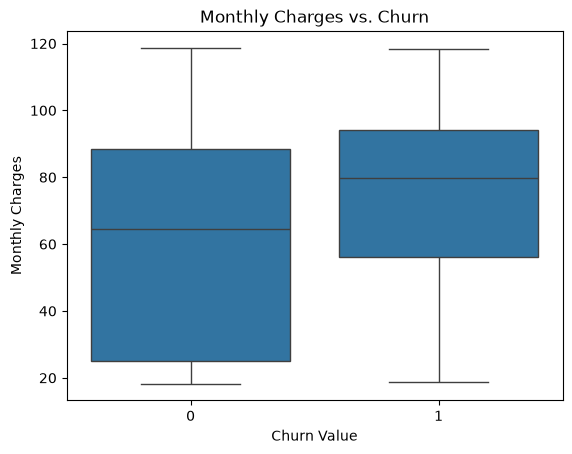

In [26]:
sns.boxplot(x='Churn Value',y='Monthly Charges',data=cust_churn_df)
plt.title('Monthly Charges vs. Churn')
plt.show()

#### Observations
- Customers who churn generally have higher monthly charges than customers who remain, as indicated by the higher median monthly charge.
- The middle 50% of monthly charges for churned customers is concentrated at higher values than for retained customers, suggesting that customers paying higher monthly fees may be more likely to leave.
- No significant outliers are observed, suggesting that monthly charges are relatively consistent across the customer base.

### Total Charges

In [27]:
cust_churn_df['Total Charges'] = pd.to_numeric(
    cust_churn_df['Total Charges'].replace(" ", np.nan),
    errors='coerce'
)

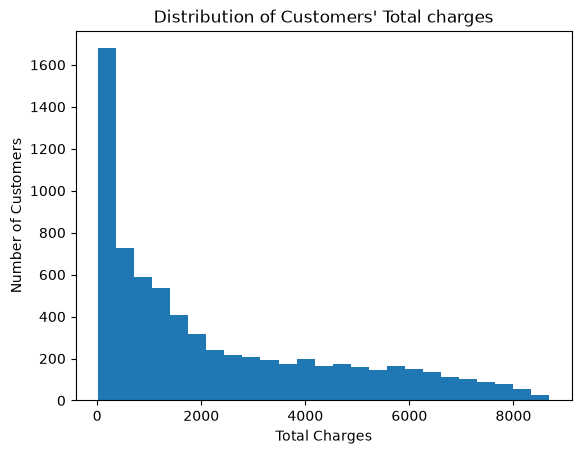

In [28]:
plt.hist(cust_churn_df['Total Charges'].dropna(),
         bins='auto')
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customers' Total charges")
plt.show()


#### Observation
- The distribution of total charges is positively (right) skewed. Most customers have relatively low accumulated charges, while progressively fewer customers have very high total charges. This pattern is expected because total charges accumulate over time and are influenced by customer tenure.

### Total Charges vs. Churn Value

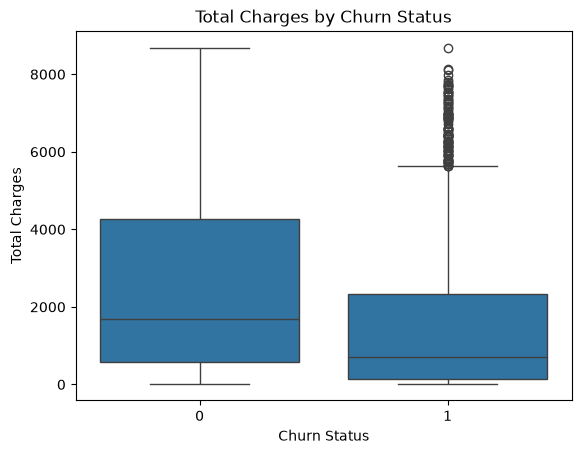

In [29]:
sns.boxplot(
    x="Churn Value",
    y="Total Charges",
    data=cust_churn_df
)

plt.xlabel("Churn Status")
plt.ylabel("Total Charges")
plt.title("Total Charges by Churn Status")
plt.show()

#### Observations
- Customers who remain with the company generally accumulate higher total charges because they stay subscribed for longer.
- Customers who churn generally have lower total charges than retained customers, as indicated by the lower median and lower interquartile range.
- Several high-value outliers exist among churned customers, indicating that although most customers who leave have relatively low accumulated charges, a small number of long-term, high-value customers also eventually churn.

## 9.Categorical Features

In [30]:
str_columns

CustomerID              str
Country                 str
State                   str
City                    str
Lat Long                str
Gender                  str
Senior Citizen          str
Partner                 str
Dependents              str
Phone Service           str
Multiple Lines          str
Internet Service        str
Online Security         str
Online Backup           str
Device Protection       str
Tech Support            str
Streaming TV            str
Streaming Movies        str
Contract                str
Paperless Billing       str
Payment Method          str
Total Charges        object
Churn Label             str
Churn Reason            str
dtype: object

##### **Data Understanding**

In [31]:
def summarize_categorical(df,column):
    print(f"\nColumn: {column}") 
    print(f'Number of unique values: {df[column].nunique()}')
    if df[column].nunique() <= 20:
        print(df[column].value_counts())
    else:
        print("Too many unique values to display.")

##### Geographic information
- Country
- State
- City
- Zip Code

In [32]:
geographic_columns=["Country","State","City","Zip Code"]

In [33]:
for column in geographic_columns:
    summarize_categorical(cust_churn_df,column)


Column: Country
Number of unique values: 1
Country
United States    7043
Name: count, dtype: int64

Column: State
Number of unique values: 1
State
California    7043
Name: count, dtype: int64

Column: City
Number of unique values: 1129
Too many unique values to display.

Column: Zip Code
Number of unique values: 1652
Too many unique values to display.


##### Customer Demographics
- Gender
- Senior Citizen
- Partner
- Dependents

In [34]:
demographic_columns=["Gender","Senior Citizen","Partner","Dependents"]

In [35]:
for column in demographic_columns:
    summarize_categorical(cust_churn_df,column)


Column: Gender
Number of unique values: 2
Gender
Male      3555
Female    3488
Name: count, dtype: int64

Column: Senior Citizen
Number of unique values: 2
Senior Citizen
No     5901
Yes    1142
Name: count, dtype: int64

Column: Partner
Number of unique values: 2
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Column: Dependents
Number of unique values: 2
Dependents
No     5416
Yes    1627
Name: count, dtype: int64


##### Services
###### Basic
- Phone Service
- Multiple Lines
- Internet Service
###### Value-added
- Online Security
- Online Backup
- Device Protection
- Tech Support
- Streaming TV
- Streaming Movies






In [36]:
basic_service_columns=["Phone Service","Multiple Lines","Internet Service"]

In [37]:
value_added_service_columns=["Online Security","Online Backup","Device Protection","Tech Support","Streaming TV","Streaming Movies"]

In [38]:
for column in basic_service_columns:
    summarize_categorical(cust_churn_df,column)


Column: Phone Service
Number of unique values: 2
Phone Service
Yes    6361
No      682
Name: count, dtype: int64

Column: Multiple Lines
Number of unique values: 3
Multiple Lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Column: Internet Service
Number of unique values: 3
Internet Service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


In [39]:
for column in value_added_service_columns:
    summarize_categorical(cust_churn_df,column)


Column: Online Security
Number of unique values: 3
Online Security
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Column: Online Backup
Number of unique values: 3
Online Backup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

Column: Device Protection
Number of unique values: 3
Device Protection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

Column: Tech Support
Number of unique values: 3
Tech Support
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

Column: Streaming TV
Number of unique values: 3
Streaming TV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

Column: Streaming Movies
Number of unique values: 3
Streaming Movies
No                     2785
Yes                    2

##### Account Information
- Contract
- Paperless Billing
- Payment Method



In [40]:
account_info_columns=["Contract","Paperless Billing","Payment Method"]

In [41]:
for columns in account_info_columns:
    summarize_categorical(cust_churn_df,columns)


Column: Contract
Number of unique values: 3
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

Column: Paperless Billing
Number of unique values: 2
Paperless Billing
Yes    4171
No     2872
Name: count, dtype: int64

Column: Payment Method
Number of unique values: 4
Payment Method
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


## 10.Relationship with Churn

In [42]:
for columns in geographic_columns:
    print(churn_rate(cust_churn_df,columns))


               Total_Customers  Churn_Count  Churn_rate
Country                                                
United States             7043         1869       26.54
            Total_Customers  Churn_Count  Churn_rate
State                                               
California             7043         1869       26.54
              Total_Customers  Churn_Count  Churn_rate
City                                                  
Wrightwood                  4            4       100.0
Tipton                      4            4       100.0
Truckee                     4            4       100.0
Twain                       4            4       100.0
Johannesburg                4            4       100.0
...                       ...          ...         ...
Arvin                       4            0         0.0
Atascadero                  4            0         0.0
Auberry                     4            0         0.0
Upland                     10            0         0.0
Volcano      

##### Observations
- The `Country` and `State` columns each contain only a single unique value(`United States` and `California`, respectively). Since these features have no variation across customers, they provide no predictive information and can be safely removed from the modeling process.
- The  `City` and `Zip Code` colmns contain a large number of unique values. Their high cardinality suggests they may contain location-specific information, but they require careful evaluation before being included in the model because they can increase model complexity and the risk of overfitting.

In [43]:
for columns in demographic_columns:
    print(churn_rate(cust_churn_df,columns))

        Total_Customers  Churn_Count  Churn_rate
Gender                                          
Female             3488          939       26.92
Male               3555          930       26.16
                Total_Customers  Churn_Count  Churn_rate
Senior Citizen                                          
Yes                        1142          476       41.68
No                         5901         1393       23.61
         Total_Customers  Churn_Count  Churn_rate
Partner                                          
No                  3641         1200       32.96
Yes                 3402          669       19.66
            Total_Customers  Churn_Count  Churn_rate
Dependents                                          
No                     5416         1763       32.55
Yes                    1627          106        6.52


##### Observations
- The churn rate for both values of the `Gender` feature are nearly identical, suggesting that `Gender` has little association with customer churn and is unlikely to be a strong predictor.
- The`Senior Citizen`,`Partner`, and `Dependents` features exhibit noticable differences in churn rates across their categories. This suggests that these customer demographic characteristics may contain useful predictive information for the machine learning model.

In [44]:
for columns in basic_service_columns:
    print(churn_rate(cust_churn_df,columns))

               Total_Customers  Churn_Count  Churn_rate
Phone Service                                          
Yes                       6361         1699       26.71
No                         682          170       24.93
                  Total_Customers  Churn_Count  Churn_rate
Multiple Lines                                            
Yes                          2971          850       28.61
No                           3390          849       25.04
No phone service              682          170       24.93
                  Total_Customers  Churn_Count  Churn_rate
Internet Service                                          
Fiber optic                  3096         1297       41.89
DSL                          2421          459       18.96
No                           1526          113        7.40


##### Observations
- The churn rates for customers with and without `Phone Service` are very similar. This suggests that `Phone Service` alone has little association with customer churn and is unlikely to be a strong standalone predictor.
- Customers with **multiple phone lines** exhibit a slightly higher churn rate than those without multiple lines. However, the differences are relatively small, suggesting that this feature may provide only limited predictive value on its own.
- The churn rate varies substantially across `Internet Service` types. This strong variation suggests that **internet service** type is likely to be an important predictor of customer churn.

In [45]:
for columns in value_added_service_columns:
    print(churn_rate(cust_churn_df,columns))

                     Total_Customers  Churn_Count  Churn_rate
Online Security                                              
No                              3498         1461       41.77
Yes                             2019          295       14.61
No internet service             1526          113        7.40
                     Total_Customers  Churn_Count  Churn_rate
Online Backup                                                
No                              3088         1233       39.93
Yes                             2429          523       21.53
No internet service             1526          113        7.40
                     Total_Customers  Churn_Count  Churn_rate
Device Protection                                            
No                              3095         1211       39.13
Yes                             2422          545       22.50
No internet service             1526          113        7.40
                     Total_Customers  Churn_Count  Churn_rate
Tech Sup

##### Observations
- The `Online Security` and `Tech Support` features exhibit very similar churn rate patterns, suggesting they may capture related aspects of customer behavior.
- Similarly, `Online Backup` and `Device Protection`, as well as `Streaming TV` and `Streaming Movies`, display comparable churn rate distributions. These similarities indicate that some service-related features may contain overlapping information, which can be investigated further during feature selection.


In [46]:
for columns in account_info_columns:
    print(churn_rate(cust_churn_df,columns))

                Total_Customers  Churn_Count  Churn_rate
Contract                                                
Month-to-month             3875         1655       42.71
One year                   1473          166       11.27
Two year                   1695           48        2.83
                   Total_Customers  Churn_Count  Churn_rate
Paperless Billing                                          
Yes                           4171         1400       33.57
No                            2872          469       16.33
                           Total_Customers  Churn_Count  Churn_rate
Payment Method                                                     
Electronic check                      2365         1071       45.29
Mailed check                          1612          308       19.11
Bank transfer (automatic)             1544          258       16.71
Credit card (automatic)               1522          232       15.24


##### Observations
- The `Contract` feature exhibits substantial differences in churn rates across its categories. This strong relationship suggests that contract type is one of the most informative predictors of customer churn, with longer-term contracts being associated with much higher customer retention.
- Customers who use `Paperless Billing` have a noticeably higher churn rate than those who do not. This indicates that paperless billing may be associated with customer churn and could provide useful predictive information for the model.
- Churn rates vary across `Payment Method`s. Electronic check users show the highest churn rate, while mailed checks, bank transfers, and credit card payments show lower, similar rates, making payment type an informative feature.

## 11.Correlation Analysis

In [47]:
df=cust_churn_df[[ "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "Churn Value"]]

In [48]:
corr_matrix=df.corr()
corr_matrix

,Tenure Months,Monthly Charges,Total Charges,Churn Value
Tenure Months,1.000000,0.247900,0.825880,-0.352229
Monthly Charges,0.247900,1.000000,0.651065,0.193356
Total Charges,0.825880,0.651065,1.000000,-0.199484
Churn Value,-0.352229,0.193356,-0.199484,1.000000


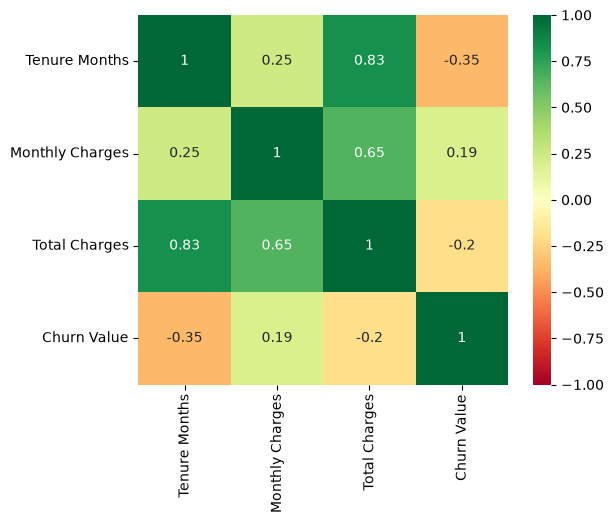

In [49]:
sns.heatmap(corr_matrix, 
            annot=True, 
            cmap='RdYlGn', 
            vmin=-1, 
            vmax=1, 
            square=True)
plt.show()

##### Observaions
- `Tenure Months` and `Total Charges` exhibit a very strong positive correlation **(0.83)**. This indicates that customers with longer subscription durations generally accumulate higher total charges, which is expected since total charges increase over time.

- `Monthly Charges` and `Total Charges` have a strong positive correlation **(0.65)**, suggesting that customers with higher monthly fees tend to accumulate higher total charges.

- `Tenure Months` and `Monthly Charges` show only a weak positive correlation **(0.25)**. This suggests that the length of a customer's subscription has only a limited relationship with the amount they pay each month.

- `Tenure Months` has a moderate negative correlation with `Churn Value` **(-0.35)** ,indicating that customers with longer tenures are generally less likely to churn.

- `Monthly Charges` exhibits a weak positive correlation **(0.19)** with churn, suggesting that customers with higher monthly charges have a slightly greater tendency to leave the company.

- `Total Charges` has a weak negative correlation **(-0.20)** with churn, indicating that customers with higher accumulated charges are generally less likely to churn.


## 12.Preliminary Feature Assesement

| Feature | Initial Assessment | Reason |
|---------|--------------------|--------|
| CustomerID | Remove | Unique identifier with no predictive value. |
| Count | Remove | Constant value for every customer. |
| Country | Remove | Contains only one unique value (United States). |
| State | Remove | Contains only one unique value (California). |
| City | Investigate Further | High-cardinality feature that may capture regional churn patterns. |
| Zip Code | Investigate Further | High-cardinality feature that may contain geographic information. |
| Latitude | Investigate Further | Geographic coordinate; usefulness should be evaluated further. |
| Longitude | Investigate Further | Geographic coordinate; usefulness should be evaluated further. |
| Gender | Weak Predictor | Very similar churn rates between males and females. |
| Senior Citizen | Moderate Predictor | Noticeable difference in churn rate between groups. |
| Partner | Moderate Predictor | Churn rates differ between customers with and without partners. |
| Dependents | Moderate Predictor | Churn rates differ between customers with and without dependents. |
| Phone Service | Weak Predictor | Similar churn rates for both categories. |
| Multiple Lines | Moderate Predictor | Some difference in churn rate across categories. |
| Internet Service | Strong Predictor | Large differences in churn rate between service types. |
| Online Security | Strong Predictor | Customers without online security churn considerably more often. |
| Online Backup | Moderate Predictor | Moderate differences in churn rate between categories. |
| Device Protection | Moderate Predictor | Moderate differences in churn rate between categories. |
| Tech Support | Strong Predictor | Customers without tech support have much higher churn rates. |
| Streaming TV | Weak Predictor | Only small differences in churn rates. |
| Streaming Movies | Weak Predictor | Only small differences in churn rates. |
| Contract | Strong Predictor | One of the strongest relationships with churn observed during EDA. |
| Paperless Billing | Moderate Predictor | Customers using paperless billing have higher churn rates. |
| Payment Method | Strong Predictor | Electronic check customers exhibit substantially higher churn rates. |
| Tenure Months | Strong Predictor | Moderate negative correlation with churn and clear separation in boxplots. |
| Monthly Charges | Moderate Predictor | Weak positive correlation with churn. |
| Total Charges | Moderate Predictor | Weak negative correlation with churn and strong relationship with tenure. |
| CLTV | Exclude for Modeling | Proprietary engineered metric with unknown calculation methodology, posing a potential risk of information leakage. |
| Churn Value | Target | Binary encoded column for churning. |
| Churn Score | Remove | IBM-generated predictive score that introduces target leakage. |
| Churn Label | Remove | Duplicate representation of the target variable (`Churn Value`). |
| Churn Reason | Remove | Available only after a customer churns, resulting in target leakage. |


> **Note:** These assessments are based on exploratory data analysis and domain knowledge. Final feature selection will be performed during the preprocessing and model development stages.

## 13.Key Findings


The exploratory data analysis revealed several important insights into customer churn and the characteristics of the dataset:

- The dataset contains **7,043 customer records** with **no duplicate entries**, ensuring each observation represents a unique customer.

- Most features contain **no missing values**. The only missing values appear in **`Churn Reason`**, which are expected because this information is only available after a customer has churned. Consequently, this feature introduces target leakage and should not be used for model training.

- The target variable is **imbalanced**, with significantly more customers remaining (`Churn Value = 0`) than churning (`Churn Value = 1`). This imbalance should be considered during model evaluation, making metrics such as **Recall**, **Precision**, and **F1-score** more informative than accuracy alone.

- **Customer tenure** is one of the strongest indicators of churn. Customers who have been with the company for a longer period are generally less likely to leave.

- Customers with **higher monthly charges** exhibit a greater tendency to churn, while customers with **higher total charges** generally have lower churn rates due to their longer relationship with the company.

- Among the categorical features, **Contract Type**, **Internet Service**, **Online Security**, **Tech Support**, and **Payment Method** demonstrate the strongest relationships with customer churn.

- Customers with **month-to-month contracts** have substantially higher churn rates than customers with one-year or two-year contracts.

- Customers using **Fiber Optic** internet service exhibit considerably higher churn rates than customers using DSL or those without internet service.

- Customers without **Online Security** or **Tech Support** churn at significantly higher rates, suggesting these services may contribute to customer retention.

- Geographic features such as **Country** and **State** provide no predictive value because they contain only a single unique value, while **CustomerID**, **Count**, **Churn Label**, **Churn Score**, and **Churn Reason** should be excluded during model development due to redundancy or target leakage.

- Correlation analysis indicates that **Tenure Months** and **Total Charges** are strongly positively correlated, while **Tenure Months** has the strongest negative correlation with churn among the numerical features.